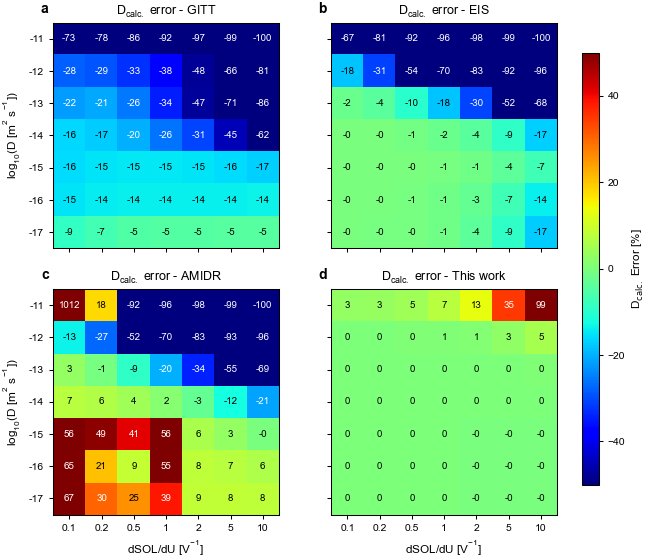

In [2]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# =============================================================================
# Publication-ready plotting configuration
# =============================================================================

# Double-column journal-style figure dimensions for a 2x2 grid
FIG_WIDTH = 6.75  # inch
FIG_HEIGHT = 6.0  # inch

# Output directory
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update(
    {
        # Typography
        "font.family": "Arial",
        "font.size": 8.0,
        "axes.labelsize": 8.5,
        "axes.titlesize": 9.0,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "legend.fontsize": 7.0,
        # Axes / lines
        "axes.linewidth": 0.75,
        "xtick.major.width": 0.75,
        "ytick.major.width": 0.75,
        "xtick.major.size": 3.0,
        "ytick.major.size": 3.0,
        # Text rendering
        "mathtext.default": "regular",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "path",
        # Figure saving
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    }
)

# =============================================================================
# Data Preparation & Parameters
# =============================================================================

D_values = np.array([1e-11, 1e-12, 1e-13, 1e-14, 1e-15, 1e-16, 1e-17])
dSOLdU_steps = [0.1, 0.2, 0.5, 1, 2, 5, 10]

# Y-axis labels as log10(D) -> [-11, -12, ..., -17]
log_D_labels = [int(np.log10(d)) for d in D_values]

# Create a 2D grid of True D values matching the file data structure:
# Row = D, Column = dSOL/dU
D_true_grid = np.repeat(D_values[:, np.newaxis], len(dSOLdU_steps), axis=1)

# Define subplot configuration: (File Name, Plot Title, Panel Label)
# Order: North-West, North-East, South-West, South-East
methods_config = [
    ("GITT", "GITT", "a"),
    ("EIS", "EIS", "b"),
    ("AMIDR", "AMIDR", "c"),
    ("NewMethod", "This work", "d"),
]


def load_and_calc_error(filename):
    """Loads flat D data, reshapes to 7x7, and calculates percentage error."""
    filepath = Path(f"{filename}.txt")

    if filepath.exists():
        D_calc_flat = np.loadtxt(filepath)
    else:
        # Fallback: Generate dummy data if files are not present for testing
        print(
            f"Warning: '{filepath}' not found. Generating dummy data for preview."
        )
        np.random.seed(sum(map(ord, filename)))
        noise = np.random.uniform(-0.45, 0.45, size=D_true_grid.size)
        D_calc_flat = D_true_grid.flatten() * (1 - noise)

    D_calc = D_calc_flat.reshape(len(D_values), len(dSOLdU_steps))

    # Relative error calculation (matching your example: (D_calc / D_true - 1) * 100)
    error_percent = (D_calc / D_true_grid - 1) * 100.0
    return error_percent


# =============================================================================
# Figure Generation
# =============================================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0.12, "hspace": 0.18},
)

for idx, (ax, (file_key, title, panel_label)) in enumerate(
    zip(axes.flat, methods_config)
):
    error_matrix = load_and_calc_error(file_key)

    # Plot Heatmap
    im = ax.imshow(
        error_matrix, cmap="jet", vmin=-50, vmax=50, aspect="equal", origin="upper"
    )

    # Title with method name
    ax.set_title(f"$D_{{calc.}}$ error - {title}", pad=6)

    # Panel label (a, b, c, d) placed just above the top-left corner of each subplot
    ax.text(
        -0.02,
        1.03,
        panel_label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10.0,
        fontweight="bold",
    )

    # Annotate values inside the heatmap cells
    for i in range(len(D_values)):
        for j in range(len(dSOLdU_steps)):
            val = error_matrix[i, j]
            # Contrast logic for 'jet' colormap
            color = "k" if (-20 < val < 26) else "w"
            ax.text(
                j,
                i,
                f"{val:.0f}",
                ha="center",
                va="center",
                color=color,
                fontsize=7.0,
            )

    # Ticks configuration
    ax.set_xticks(range(len(dSOLdU_steps)))
    ax.set_xticklabels(dSOLdU_steps)
    ax.set_yticks(range(len(D_values)))
    ax.set_yticklabels(log_D_labels)

    ax.tick_params(
        axis="both", which="both", direction="out", top=False, right=False
    )

    # Set outer axis labels only
    if idx in [2, 3]:  # Bottom row
        ax.set_xlabel("dSOL/dU [V$^{-1}$]")
    if idx in [0, 2]:  # Left column
        ax.set_ylabel(r"log$_{10}$(D [m$^2$ s$^{-1}$])")

# =============================================================================
# Colorbar & Layout Adjustments
# =============================================================================

# Adjust subplots to make room for the colorbar on the right
fig.subplots_adjust(left=0.10, right=0.88, bottom=0.10, top=0.92)

# Add a dedicated axis for the shared colorbar
cbar_ax = fig.add_axes([0.90, 0.15, 0.025, 0.72])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r"$D_{\mathrm{calc.}}$ Error [%]")
cbar.ax.tick_params(direction="out")

# =============================================================================
# Export
# =============================================================================

output_base = FIGURE_DIR / "diffusion_methods_error_comparison"

# Vector format — required
fig.savefig(
    output_base.with_suffix(".svg"),
    format="svg",
    dpi=600,
)

# Raster format — good for quick preview
fig.savefig(
    output_base.with_suffix(".png"),
    format="png",
    dpi=600,
)

plt.show()